# Chan et al. 2021 — Lung (SCLC) · 03 Signatures

Raw signature UMAPs (Gast/pSom/Crest) in house `(3.5,1.5)` style with external colorbars, then
**Gate 2** on the module geography. Deliverable UMAPs show **raw** per-cell scores (smoothing aids
the geography read but the deliverable is the honest per-cell readout).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load `manifold.h5ad`

In [4]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0])
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 50998
Gast: 80/81 genes present
pSom: 96/98 genes present
Crest: 104/104 genes present


### Gate 2 — module geography (non-branching)
Gast and pSom **co-vary** (positive smoothed r — overlap, not competitive cross-repression) and
Crest is an **inverse/terminal gradient** rising where pSom falls (strong negative pSom↔Crest r).
This is the non-branching case (§1): a single embryonic axis, not a hub diverging into two
gradient-opposed arms. It **passes Gate 2 (GO)**; with no bifurcation, **Gate 3 is NA**. Crest does
not enrich a Gast arm (there are no arms), so no inversion flag.

In [6]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
# inverse-gradient vs co-expression-hub test (pSom & Crest)
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = inverse gradient, not a hub)')
# Gast/pSom overlap test
gz = (adata.obs['Gast']-adata.obs['Gast'].mean())/adata.obs['Gast'].std()
joint_gp = ((gz>0.5)&(pz>0.5)).mean(); exp_gp=(gz>0.5).mean()*(pz>0.5).mean()
print(f'joint Gast&pSom-high enrichment = {joint_gp/exp_gp:.2f} (>1 = overlap/co-expression, not competition)')
# gate call is guarded by the computed enrichment ratios (non-branching signature):
#   Gast/pSom overlap (co-expression enrichment > 1) + inverse terminal Crest (pSom&Crest-high enrichment < 1)
overlap = (joint_gp/exp_gp) > 1.0
inverse = (joint/exp) < 1.0
assert overlap and inverse, f'Gate-2 non-branching premises unmet: Gast/pSom enrich={joint_gp/exp_gp:.2f}, pSom/Crest enrich={joint/exp:.2f}'
print('Gate 2: Gast/pSom overlap + inverse terminal Crest gradient -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.28
  Crest_sm vs Gast_sm: r = -0.35
  Crest_sm vs pSom_sm: r = -0.89
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = +0.477
  pSom_sm: rho = -0.157
  Crest_sm: rho = +0.075
joint pSom&Crest-high enrichment = 0.20 (<1 = inverse gradient, not a hub)
joint Gast&pSom-high enrichment = 1.42 (>1 = overlap/co-expression, not competition)
Gate 2: Gast/pSom overlap + inverse terminal Crest gradient -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Deliverables — raw signature UMAPs + external colorbars (house style)
`figsize=(3.5,1.5)`, `cmap='plasma'`, shared house orientation (`X_umap_lin`), one external colorbar
per module in `colorbars/`.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


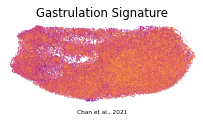

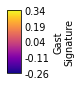

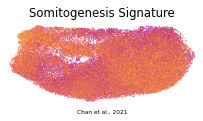

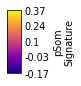

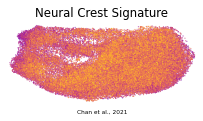

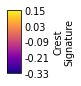

In [8]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=6, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Chan et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save `signatures.h5ad`

In [10]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (50998, 24117)
